In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
s = pd.Series([100, 103, 102, 108, 107])

In [ ]:
s.diff()

0    NaN
1    3.0
2   -1.0
3    6.0
4   -1.0
dtype: float64

In [4]:
s.diff(2)

0    NaN
1    NaN
2    2.0
3    5.0
4    5.0
dtype: float64

In [5]:
s.pct_change()

0         NaN
1    0.030000
2   -0.009709
3    0.058824
4   -0.009259
dtype: float64

In [6]:
# 실습1 1시 35  엔진2 s_11

In [7]:
CM = '..//data//21_cmapss_fd001_sample.csv'
TS = '..//data//21_engine1_timestamp_sample.csv'

In [8]:
df = pd.read_csv(CM)

In [9]:
# ── [실습 1] 변화량으로 급변 탐지하기 (엔진2·s_11) ──────────────────────────
e2 = df[df['unit_nr'] == 2].reset_index(drop=True)

In [10]:
d = e2['s_11'].diff()

In [11]:
d.head()

0      NaN
1   -0.203
2    0.030
3    0.061
4   -0.230
Name: s_11, dtype: float64

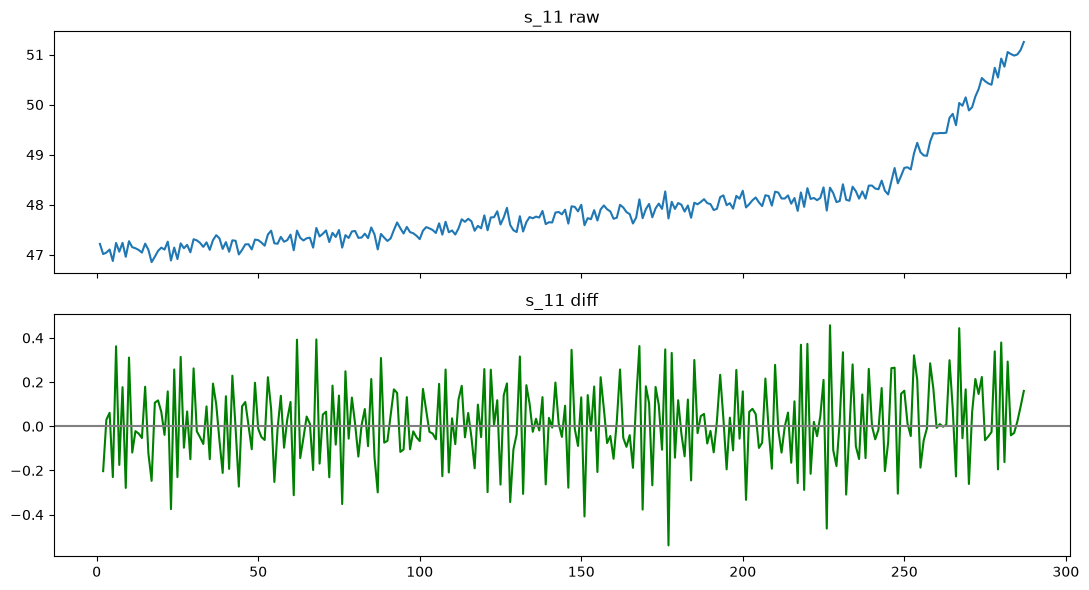

실습1 최대 급변: 0.54


In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.plot(e2['time_cycles'], e2['s_11']); ax1.set_title('s_11 raw')
ax2.plot(e2['time_cycles'], d, color='green')
ax2.axhline(0, color='gray')
ax2.set_title('s_11 diff'); plt.tight_layout()
plt.show()
print('실습1 최대 급변:', round(d.abs().max(), 2))

In [13]:
d.abs().idxmax()

176

In [14]:
d.iloc[176]

np.float64(-0.5390000000000015)

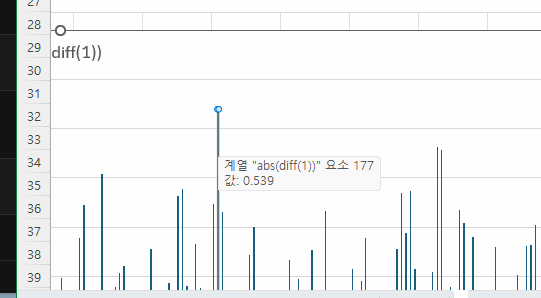

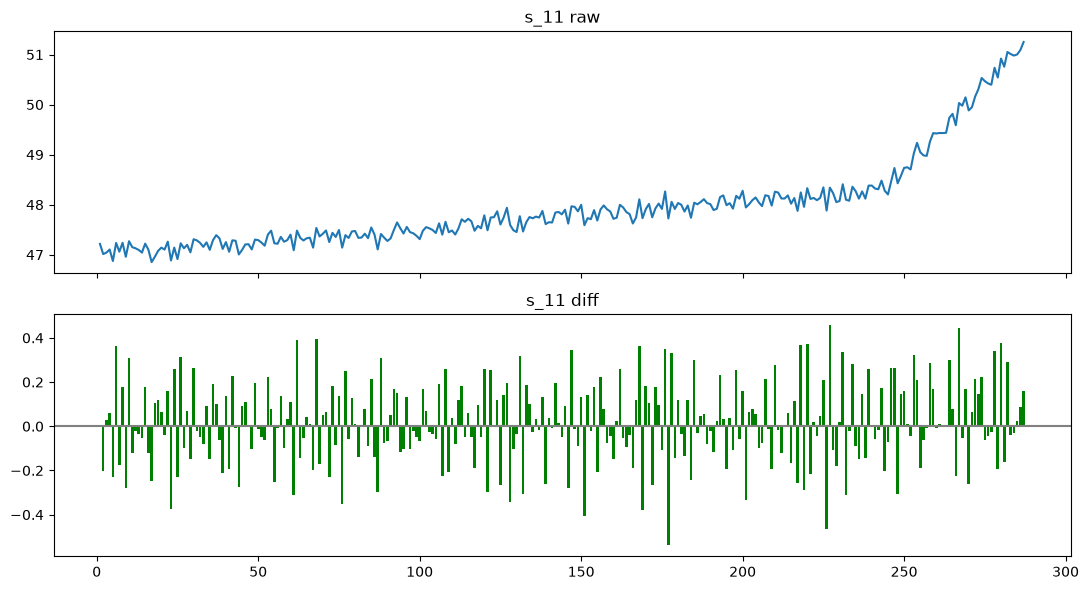

In [17]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.plot(e2['time_cycles'], e2['s_11']); ax1.set_title('s_11 raw')
ax2.bar(e2['time_cycles'], d, color='green')
ax2.axhline(0, color='gray')
ax2.set_title('s_11 diff'); plt.tight_layout()
plt.show()

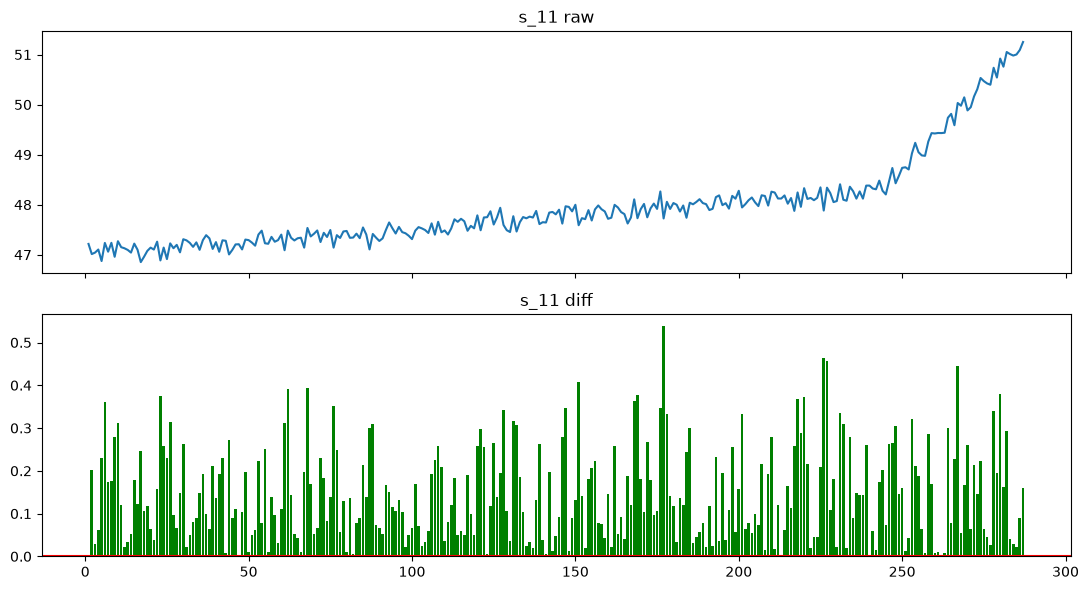

In [21]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.plot(e2['time_cycles'], e2['s_11']); ax1.set_title('s_11 raw')
ax2.bar(e2['time_cycles'], abs(d), color='green')
ax2.axhline(0, color='red')
ax2.set_title('s_11 diff'); plt.tight_layout()
plt.show()

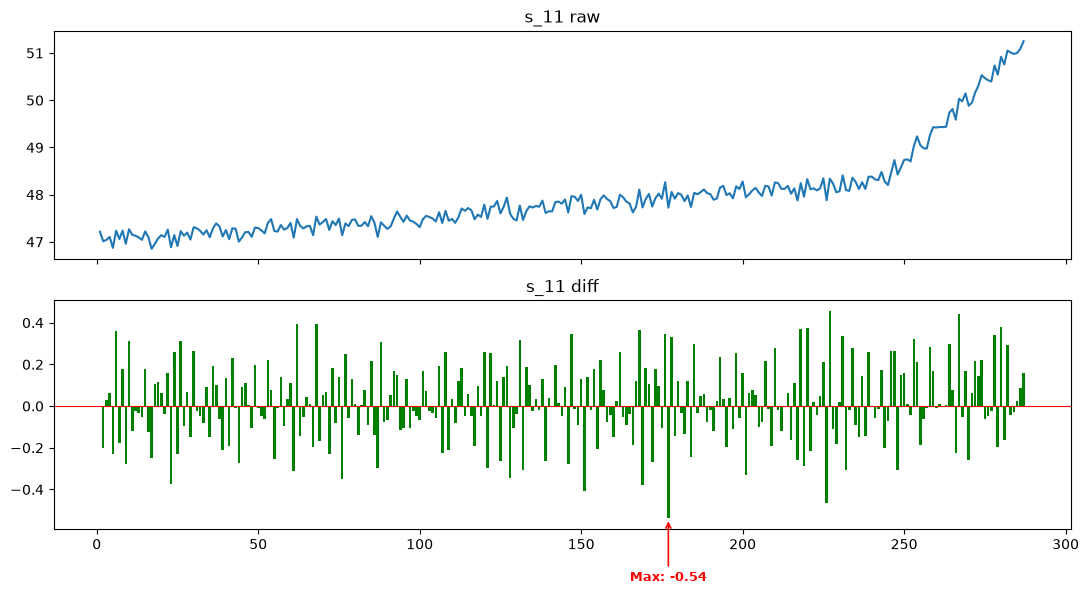

실습1 최대 급변: 0.54


In [22]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

# 1. 원본
ax1.plot(e2['time_cycles'], e2['s_11'])
ax1.set_title('s_11 raw')

# 2. 차분 (막대)
ax2.bar(e2['time_cycles'], d, color='green', width=0.8)
ax2.axhline(0, color='red', linewidth=0.8)
ax2.set_title('s_11 diff')

# ── 최대값 표기 ──
max_idx = d.abs().idxmax()          # 절댓값 기준 최대 위치
max_val = d.loc[max_idx]
max_x   = e2.loc[max_idx, 'time_cycles']

ax2.annotate(
    f'Max: {max_val:.2f}',
    xy=(max_x, max_val),
    xytext=(max_x, max_val + (0.3 if max_val > 0 else -0.3)),
    ha='center',
    arrowprops=dict(arrowstyle='->', color='red', lw=1.2),
    fontsize=9, color='red', fontweight='bold'
)

plt.tight_layout()
plt.show()

print('실습1 최대 급변:', round(d.abs().max(), 2))

In [24]:
# 실습2 2시 15분 엔진2·s_3

In [25]:
# ── [실습 2] 추세·변동성·변화량 종합 관찰 (엔진2·s_3) ───────────────────────
col = 's_3'

In [26]:
ma = e2[col].rolling(20).mean()

In [28]:
sd = e2[col].rolling(20).std()

In [29]:
dd = e2[col].diff()

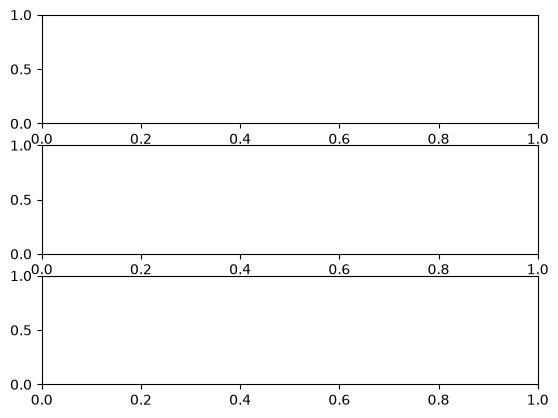

In [30]:
a, b=plt.subplots(3, 1)

In [31]:
b[0]

<Axes: >

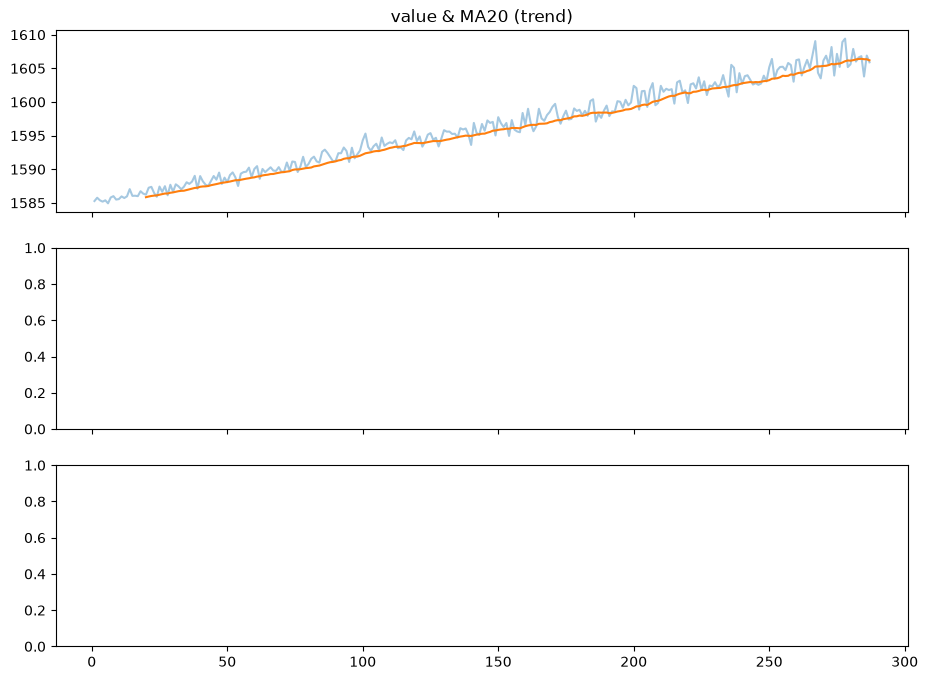

In [32]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(e2['time_cycles'], e2[col], alpha=0.4)
axes[0].plot(e2['time_cycles'], ma)
axes[0].set_title('value & MA20 (trend)')
plt.show()

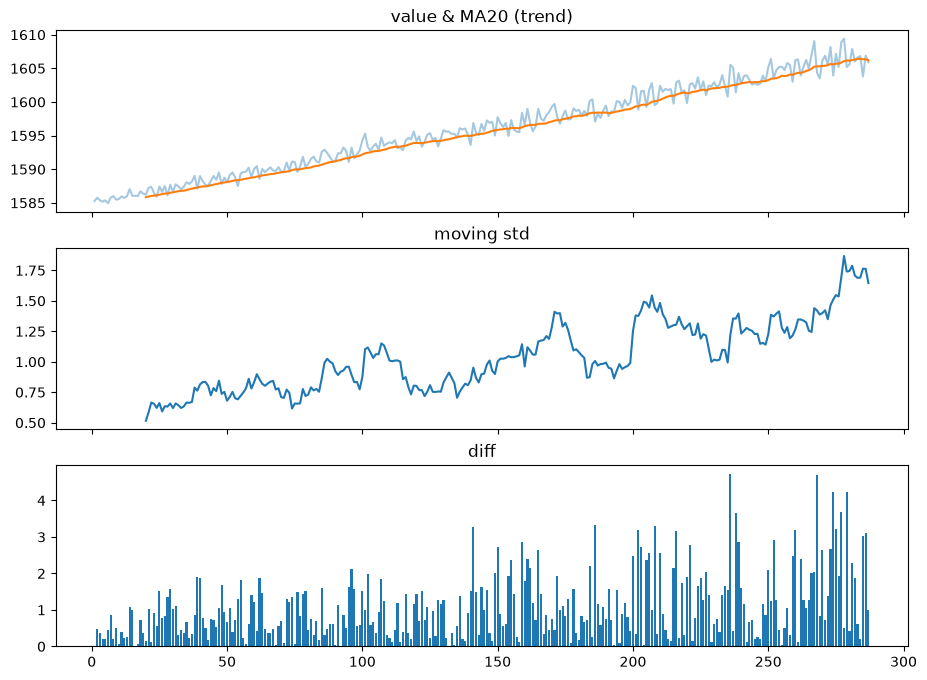

In [36]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(e2['time_cycles'], e2[col], alpha=0.4)
axes[0].plot(e2['time_cycles'], ma)
axes[0].set_title('value & MA20 (trend)')
axes[1].plot(e2['time_cycles'], sd)
axes[1].set_title('moving std')
axes[2].bar(e2['time_cycles'], abs(dd))
axes[2].set_title('diff')
plt.show()

In [37]:
#실습 3 2시 33분

In [38]:
# s_4

In [39]:
ts = pd.read_csv(TS)

In [40]:
ts.head()

,timestamp,s_2,s_3,s_4,s_7,s_11
0,2024-01-01 00:00:00,640.69,1585.21,1399.30,554.17,46.931
1,2024-01-01 01:00:00,641.13,1585.55,1401.18,554.36,46.857
2,2024-01-01 02:00:00,641.25,1584.72,1400.84,554.00,47.220
3,2024-01-01 03:00:00,641.97,1585.94,1401.26,554.13,47.152
4,2024-01-01 04:00:00,641.58,1585.72,1401.36,553.87,46.956


In [41]:
ts.isna().sum().sum()

np.int64(0)

In [42]:
ts['timestamp'] = pd.to_datetime(ts['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

In [43]:
ts['timestamp']

0     2024-01-01 00:00:00
1     2024-01-01 01:00:00
2     2024-01-01 02:00:00
3     2024-01-01 03:00:00
4     2024-01-01 04:00:00
              ...        
187   2024-01-08 19:00:00
188   2024-01-08 20:00:00
189   2024-01-08 21:00:00
190   2024-01-08 22:00:00
191   2024-01-08 23:00:00
Name: timestamp, Length: 192, dtype: datetime64[us]

In [44]:
ts.isna().sum().sum()

np.int64(0)

In [45]:
ts.index

RangeIndex(start=0, stop=192, step=1)

In [46]:
ts = ts.set_index('timestamp')

In [47]:
ts

,s_2,s_3,s_4,s_7,s_11
timestamp,,,,,
2024-01-01 00:00:00,640.69,1585.21,1399.30,554.17,46.931
2024-01-01 01:00:00,641.13,1585.55,1401.18,554.36,46.857
2024-01-01 02:00:00,641.25,1584.72,1400.84,554.00,47.220
2024-01-01 03:00:00,641.97,1585.94,1401.26,554.13,47.152
2024-01-01 04:00:00,641.58,1585.72,1401.36,553.87,46.956
...,...,...,...,...,...
2024-01-08 19:00:00,647.63,1606.39,1418.65,549.65,50.814
2024-01-08 20:00:00,647.05,1608.47,1417.50,550.54,50.915
2024-01-08 21:00:00,646.84,1605.65,1417.31,549.79,50.997


In [48]:
ts.index

DatetimeIndex(['2024-01-01 00:00:00', '2024-01-01 01:00:00',
               '2024-01-01 02:00:00', '2024-01-01 03:00:00',
               '2024-01-01 04:00:00', '2024-01-01 05:00:00',
               '2024-01-01 06:00:00', '2024-01-01 07:00:00',
               '2024-01-01 08:00:00', '2024-01-01 09:00:00',
               ...
               '2024-01-08 14:00:00', '2024-01-08 15:00:00',
               '2024-01-08 16:00:00', '2024-01-08 17:00:00',
               '2024-01-08 18:00:00', '2024-01-08 19:00:00',
               '2024-01-08 20:00:00', '2024-01-08 21:00:00',
               '2024-01-08 22:00:00', '2024-01-08 23:00:00'],
              dtype='datetime64[us]', name='timestamp', length=192, freq=None)

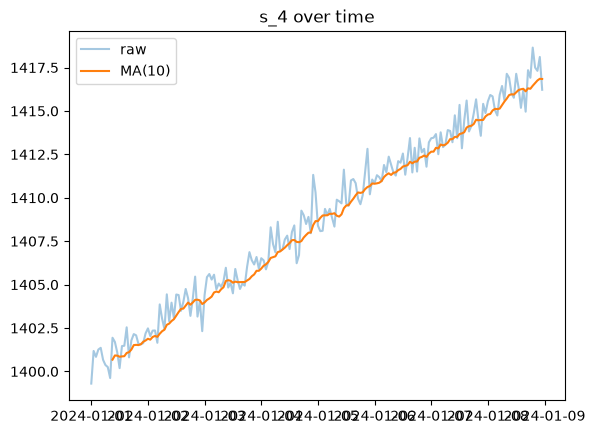

In [49]:
plt.plot(ts.index, ts['s_4'], alpha=0.4, label='raw')
plt.plot(ts.index, ts['s_4'].rolling(10).mean(), label='MA(10)')
plt.title('s_4 over time'); plt.legend();
plt.show()

In [50]:
#실습4 2시 45분

In [51]:
#  s_4

In [52]:
h6 = ts['s_4'].resample('6h').mean()
day = ts['s_4'].resample('D').mean()

In [53]:
h6

timestamp
2024-01-01 00:00:00    1400.768333
2024-01-01 06:00:00    1400.830000
2024-01-01 12:00:00    1401.378333
2024-01-01 18:00:00    1401.865000
2024-01-02 00:00:00    1402.456667
2024-01-02 06:00:00    1403.308333
2024-01-02 12:00:00    1404.215000
2024-01-02 18:00:00    1403.728333
2024-01-03 00:00:00    1405.171667
2024-01-03 06:00:00    1405.170000
2024-01-03 12:00:00    1405.068333
2024-01-03 18:00:00    1406.325000
2024-01-04 00:00:00    1406.793333
2024-01-04 06:00:00    1407.478333
2024-01-04 12:00:00    1407.613333
2024-01-04 18:00:00    1409.328333
2024-01-05 00:00:00    1408.718333
2024-01-05 06:00:00    1409.695000
2024-01-05 12:00:00    1410.346667
2024-01-05 18:00:00    1410.896667
2024-01-06 00:00:00    1411.275000
2024-01-06 06:00:00    1411.855000
2024-01-06 12:00:00    1412.328333
2024-01-06 18:00:00    1412.558333
2024-01-07 00:00:00    1413.293333
2024-01-07 06:00:00    1413.698333
2024-01-07 12:00:00    1414.371667
2024-01-07 18:00:00    1414.806667
2024-01-08

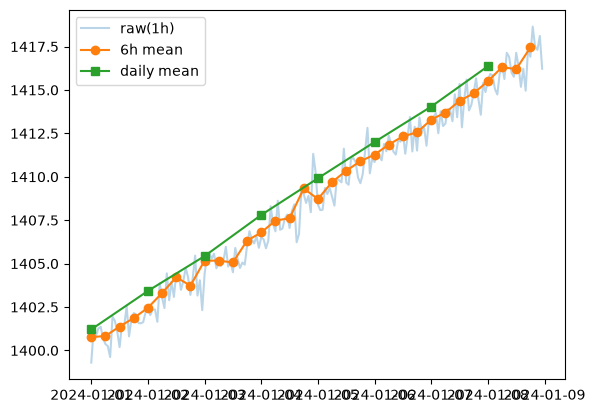

하루 평균 개수: 8


In [55]:
plt.plot(ts.index, ts['s_4'], alpha=0.3, label='raw(1h)')
plt.plot(h6.index, h6, marker='o', label='6h mean')
plt.plot(day.index, day, marker='s', label='daily mean')
plt.legend()
plt.show()
print('하루 평균 개수:', len(day))                    # 8

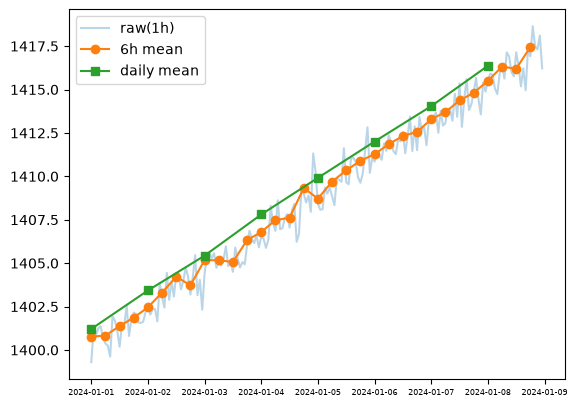

In [57]:
plt.plot(ts.index, ts['s_4'], alpha=0.3, label='raw(1h)')
plt.plot(h6.index, h6, marker='o', label='6h mean')
plt.plot(day.index, day, marker='s', label='daily mean')
plt.legend()
plt.xticks(fontsize=6)
plt.show()


In [61]:
import numpy as np

In [62]:
# ── [실습 5] 누락 시점 보간 후 재분석 ───────────────────────────────────────
s = pd.Series([10.0, np.nan, np.nan, 16.0, 18.0])

In [67]:
s

0    10.0
1     NaN
2     NaN
3    16.0
4    18.0
dtype: float64

In [68]:
s.ffill()

0    10.0
1    10.0
2    10.0
3    16.0
4    18.0
dtype: float64

In [69]:
s.bfill()

0    10.0
1    16.0
2    16.0
3    16.0
4    18.0
dtype: float64

In [63]:
#3시 15분

In [70]:
s.interpolate()

0    10.0
1    12.0
2    14.0
3    16.0
4    18.0
dtype: float64

In [66]:
ts['s_4'].isna().sum()

np.int64(0)

In [64]:
# s_4

In [71]:
s2 = ts['s_4'].copy();

In [72]:
s2.iloc[50:55] = np.nan

In [74]:
s2.isna().sum()

np.int64(5)

In [75]:
s2.interpolate().isna().sum()

np.int64(0)

In [59]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [76]:
ts['s_4']

timestamp
2024-01-01 00:00:00    1399.30
2024-01-01 01:00:00    1401.18
2024-01-01 02:00:00    1400.84
2024-01-01 03:00:00    1401.26
2024-01-01 04:00:00    1401.36
                        ...   
2024-01-08 19:00:00    1418.65
2024-01-08 20:00:00    1417.50
2024-01-08 21:00:00    1417.31
2024-01-08 22:00:00    1418.11
2024-01-08 23:00:00    1416.22
Name: s_4, Length: 192, dtype: float64

In [ ]:
#시계열을 가법 모델(additive) 로 분

In [ ]:
#seasonal_decompose()


In [77]:
#period=24는 계절 주기가 24라는 뜻입니다 (보통 시간 단위 데이터에서 하루 주기를 의미).

In [78]:
# 분해 결과를 4단 그래프

In [79]:
ts.columns

Index(['s_2', 's_3', 's_4', 's_7', 's_11'], dtype='str')

In [80]:
ts.index

DatetimeIndex(['2024-01-01 00:00:00', '2024-01-01 01:00:00',
               '2024-01-01 02:00:00', '2024-01-01 03:00:00',
               '2024-01-01 04:00:00', '2024-01-01 05:00:00',
               '2024-01-01 06:00:00', '2024-01-01 07:00:00',
               '2024-01-01 08:00:00', '2024-01-01 09:00:00',
               ...
               '2024-01-08 14:00:00', '2024-01-08 15:00:00',
               '2024-01-08 16:00:00', '2024-01-08 17:00:00',
               '2024-01-08 18:00:00', '2024-01-08 19:00:00',
               '2024-01-08 20:00:00', '2024-01-08 21:00:00',
               '2024-01-08 22:00:00', '2024-01-08 23:00:00'],
              dtype='datetime64[us]', name='timestamp', length=192, freq=None)

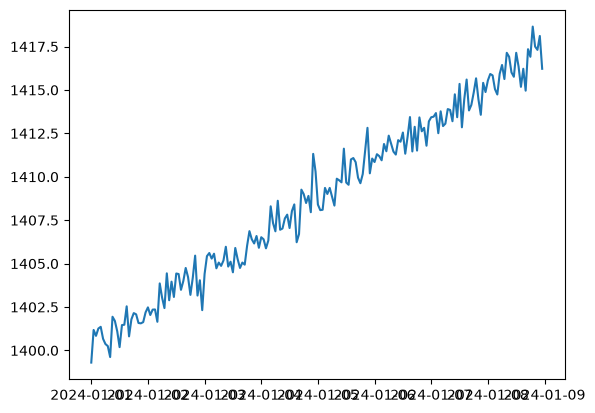

In [81]:
plt.plot(ts.index,ts['s_4'])
plt.show()

In [82]:
seasonal_decompose(ts['s_4'])

In [86]:
#시계열을 다음 세 가지 성분으로 분해하는 고전적 분해(classical decomposition) 방법입니다.

#Trend (추세): 장기적인 상승/하락 흐름
#Seasonal (계절): 일정 주기로 반복되는 패턴
#Residual (잔차): 나머지 불규칙 변동 (노이즈)

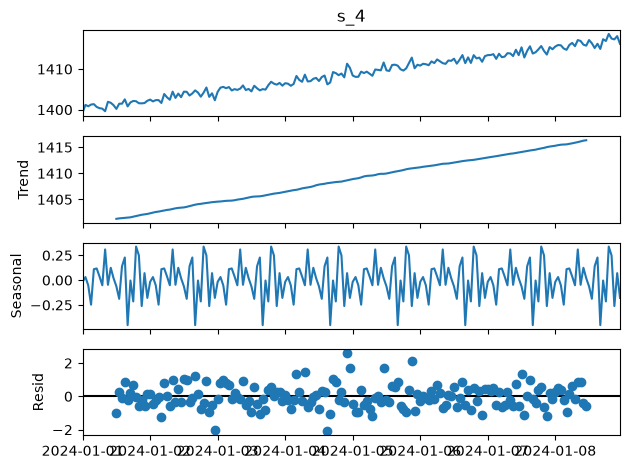

In [85]:
result=seasonal_decompose(ts['s_4'])
result.plot()
plt.tight_layout()
plt.show()

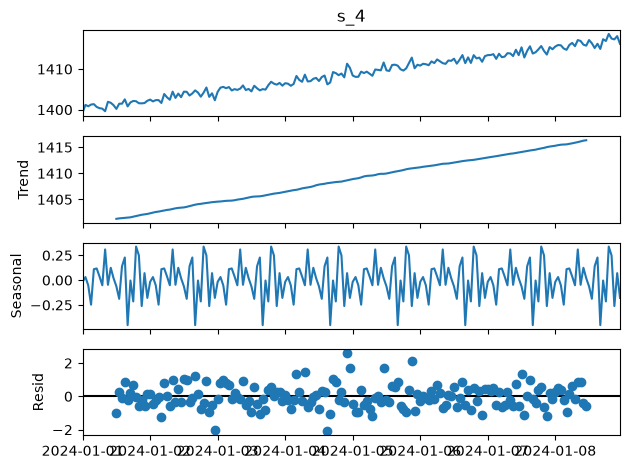

In [87]:
result=seasonal_decompose(ts['s_4'], model='additive')
result.plot()
plt.tight_layout()
plt.show()


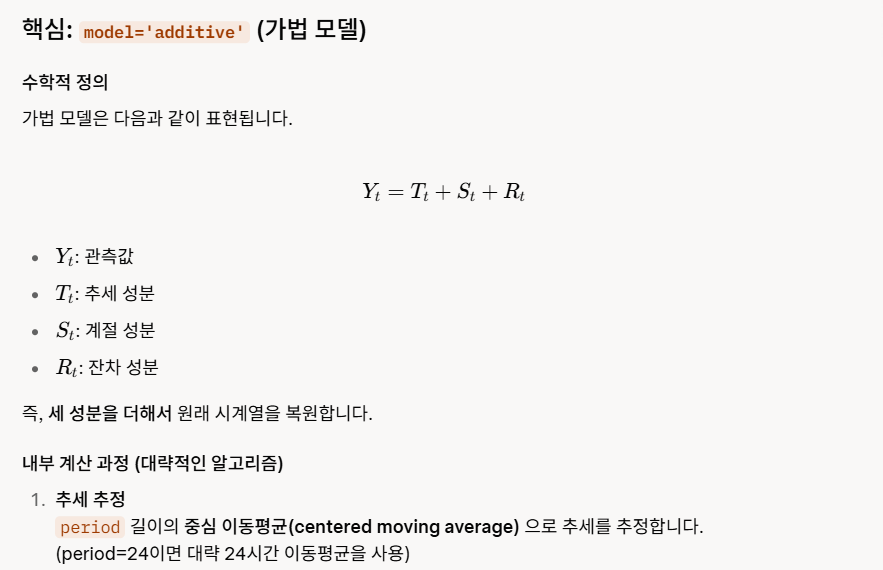

In [88]:
result

In [ ]:
result.observed

timestamp
2024-01-01 00:00:00    1399.30
2024-01-01 01:00:00    1401.18
2024-01-01 02:00:00    1400.84
2024-01-01 03:00:00    1401.26
2024-01-01 04:00:00    1401.36
                        ...   
2024-01-08 19:00:00    1418.65
2024-01-08 20:00:00    1417.50
2024-01-08 21:00:00    1417.31
2024-01-08 22:00:00    1418.11
2024-01-08 23:00:00    1416.22
Name: s_4, Length: 192, dtype: float64

In [90]:
result.trend

timestamp
2024-01-01 00:00:00   NaN
2024-01-01 01:00:00   NaN
2024-01-01 02:00:00   NaN
2024-01-01 03:00:00   NaN
2024-01-01 04:00:00   NaN
                       ..
2024-01-08 19:00:00   NaN
2024-01-08 20:00:00   NaN
2024-01-08 21:00:00   NaN
2024-01-08 22:00:00   NaN
2024-01-08 23:00:00   NaN
Name: trend, Length: 192, dtype: float64

In [92]:
result.trend.notna().sum()

np.int64(168)

In [93]:
result_df=pd.DataFrame(result.trend)

In [94]:
result_df

,trend
timestamp,
2024-01-01 00:00:00,NaN
2024-01-01 01:00:00,NaN
2024-01-01 02:00:00,NaN
2024-01-01 03:00:00,NaN
2024-01-01 04:00:00,NaN
...,...
2024-01-08 19:00:00,NaN
2024-01-08 20:00:00,NaN
2024-01-08 21:00:00,NaN


In [95]:
result_df[result.trend.notna()]

,trend
timestamp,
2024-01-01 12:00:00,1401.276667
2024-01-01 13:00:00,1401.360833
2024-01-01 14:00:00,1401.410208
2024-01-01 15:00:00,1401.464583
2024-01-01 16:00:00,1401.493542
...,...
2024-01-08 07:00:00,1415.854583
2024-01-08 08:00:00,1415.980000
2024-01-08 09:00:00,1416.121250


In [96]:
#1401.276667

In [ ]:
# 연속된 24시간 평균 두 개를 구한 뒤 다시 평균한 값입니다.

# 첫 번째 평균: 1월 1일 00시부터 23시까지의 s_4 평균
# 두 번째 평균: 1월 1일 01시부터 1월 2일 00시까지의 s_4 평균

In [98]:
ts['2024-01-01 00:00:00':'2024-01-01 23:00:00']['s_4'].mean()

np.float64(1401.2104166666668)

In [99]:

ts['2024-01-01 01:00:00':'2024-01-02 00:00:00']['s_4'].mean()

np.float64(1401.3429166666665)

In [100]:
(1401.2104166666668 + 1401.3429166666665) / 2

1401.2766666666666

In [97]:
# **중심 이동평균(Centered Moving Average)**의 가장 쉬운 예를 보여드리겠습니다

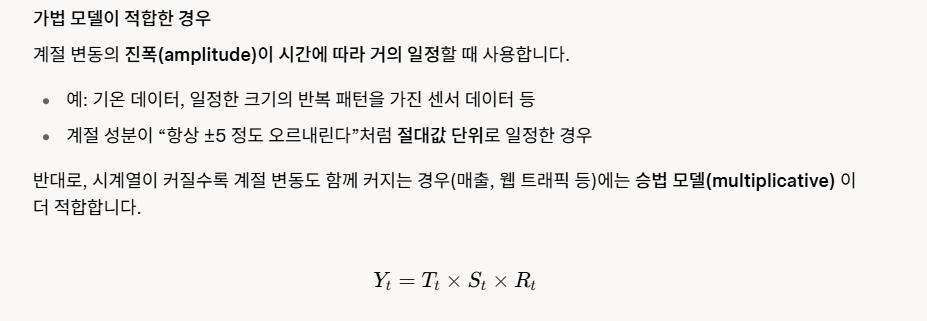

In [ ]:
seasonal_decompose(ts['s_4'], model='additive', period=24)